# Supplementary figures S1-S3 — the random forest and the band-ratio baseline

Three figures that support §2.5 and §3.2 of the main text without adding to it:

| figure | shows |
|---|---|
| S1 | recursive feature elimination: how cross-validated error grows as predictors are dropped |
| S2 | the band-ratio baseline, fitted to the same training data and scored on the same held-out folds |
| S3 | why the band ratio does not transfer: the depth/band-ratio relationship by lake segment and by scene |

### Inputs

All under `data/sup/`, staged by `zenodo_build/scripts/build_supplement_data.py`:

* `rfe_stats.csv` — the elimination run from `GlacierLakeIS2ML/RF-varimp.ipynb` (62 → 1 predictors)
* `ml_supplement_samples.parquet` — the 411,975 training samples with raw blue/green/red
  reflectance and **out-of-fold** predictions from the random forest (62 and 16 predictors) and
  from the band ratio, all on the identical segment-grouped 10-fold split
* `ml_supplement_segments.parquet` — per-segment metadata, used to pick the examples in S3
* `ml_supplement_meta.json` — band-ratio coefficients, feature lists and headline statistics

### Note on which error is quoted where

The same cross-validation yields two different MAEs depending on which samples are scored:

| samples scored | random forest, 62 predictors |
|---|---|
| all 411,975 | 0.342 m |
| the 237,136 where ICESat-2 saw water | 0.543 m |
| water, with the NDWI gate the thesis applied | 0.522 m |

42 % of training samples are dry ice, where the model correctly returns zero, so averaging over
all of them dilutes the error. S2 quotes the **water-only** figure throughout, because that is
what compares to the sonar validation and to the band ratio.

Two different NDWI gates are in play, and they belong to different runs:

* **0.23** — the threshold the thesis band-ratio fit used, and the one `build_supplement_data.py`
  applies. Every number computed in this notebook uses it.
* **0.14** — the threshold inside the elimination run in `RF-varimp.ipynb`, which is where
  `rfe_stats.csv` comes from. S1's curve is that run's own MAE, so its 62-predictor point reads
  0.519 m rather than the 0.522 m above. The two are not directly comparable, and S1's caption
  states its own definition.

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import json
import re
import shutil

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmcrameri import cm as cmc
from IPython.display import Image, display
from matplotlib.colors import LogNorm
from scipy.stats import pearsonr

# Same LaTeX handling as the main figure notebooks, so the supplement is set in the same type.
USETEX = shutil.which('latex') is not None
plt.rcParams.update({'font.size': 9, 'font.family': 'Optima', 'text.usetex': USETEX})
print('text.usetex:', USETEX)

_TEX_UNSAFE = (('–', '--'), ('’', "'"), ('−', '$-$'),
               ('·', r'$\cdot$'), ('%', r'\%'), ('_', r'\_'),
               ('>', '$>$'), ('<', '$<$'))


def tex(s):
    """Make a plain-text label safe for text.usetex. Only for strings with no maths in them."""
    if not USETEX:
        return s
    for raw, escaped in _TEX_UNSAFE:
        s = s.replace(raw, escaped)
    return s


def bold(s):
    """Under text.usetex matplotlib ignores fontweight, so ask LaTeX for the weight instead."""
    return r'\textbf{%s}' % s if USETEX else s


DSUP = 'data/sup'
meta = json.load(open(f'{DSUP}/ml_supplement_meta.json'))
rfe = pd.read_csv(f'{DSUP}/rfe_stats.csv')
smp = pd.read_parquet(f'{DSUP}/ml_supplement_samples.parquet')
seg = pd.read_parquet(f'{DSUP}/ml_supplement_segments.parquet')

NDWI_THRESH = meta['ndwi_threshold']
FEATS_16, FEATS_19 = meta['features_16'], meta['features_19_rfe']
assert len(rfe) == 62 and len(FEATS_16) == 16 and len(FEATS_19) == 19
assert len(smp) == meta['n_samples'] == 411975
print(f'{len(smp):,} samples / {smp.IS2_id.nunique():,} segments / {len(seg):,} in metadata')

# --------------------------------------------------------------- predictor names and grouping
ANGLE = re.compile(r'^(SZA|VZA_|RAA_|PhA_)')
CATEGORY_COLOR = {'band': '#1f5c99',    # log reflectance in one Sentinel-2 band
                  'combo': '#117a4b',   # a ratio or difference of two log reflectances, or NDWI
                  'angle': '#b5341f',   # viewing/illumination geometry, needs L1C metadata
                  'aux': '#767676'}     # atmospheric and scene-classification layers
CATEGORY_LABEL = {'band': 'single-band log reflectance',
                  'combo': 'band combination',
                  'angle': 'viewing / illumination angle (Level-1C metadata)',
                  'aux': 'atmospheric or scene-classification layer'}


def category(f):
    if ANGLE.match(f):
        return 'angle'
    if f.startswith(('ratio_', 'diff_')) or f == 'ndwi':
        return 'combo'
    if re.fullmatch(r'B\d+A?_log', f):
        return 'band'
    return 'aux'


def pretty(f):
    """Predictor label in the notation the manuscript uses."""
    m = re.fullmatch(r'B(\d+A?)_log', f)
    if m:
        return rf'$\ln B_{{{m.group(1)}}}$'
    m = re.fullmatch(r'ratio_logB(\d+A?)_logB(\d+A?)', f)
    if m:
        return rf'$\ln B_{{{m.group(1)}}} / \ln B_{{{m.group(2)}}}$'
    m = re.fullmatch(r'diff_logB(\d+A?)_logB(\d+A?)', f)
    if m:
        return rf'$\ln B_{{{m.group(1)}}} - \ln B_{{{m.group(2)}}}$'
    m = re.fullmatch(r'(VZA|RAA)_B(\d+A?)_cos', f)
    if m:
        return rf'$\cos \mathrm{{{m.group(1)}}}(B_{{{m.group(2)}}})$'
    m = re.fullmatch(r'PhA_B(\d+A?)', f)
    if m:
        return rf'$\mathrm{{PhA}}(B_{{{m.group(1)}}})$'
    return {'SZA_cos': r'$\cos \mathrm{SZA}$', 'ndwi': 'NDWI',
            'AOT_log': r'$\ln \mathrm{AOT}$', 'WVP_log': r'$\ln \mathrm{WVP}$',
            'cloudScore_log': r'$\ln$ cloudScore'}.get(f, tex(f))


# every predictor must be recognised by both helpers, or a label silently falls through
_unknown = [f for f in rfe.eliminated if pretty(f) == tex(f) and category(f) != 'aux']
assert not _unknown, f'unlabelled predictors: {_unknown}'
print('predictor categories:', pd.Series([category(f) for f in rfe.eliminated]).value_counts().to_dict())


# --------------------------------------------------------------- scoring helpers
OBS = smp.depth.to_numpy(dtype=float)
WET = OBS > 0           # ICESat-2 retrieved a depth here; dry ice is excluded throughout S2,
                        # because the band ratio returns zero there by construction


def score(pred, mask=WET):
    o, q = OBS[mask], np.asarray(pred, dtype=float)[mask]
    e = q - o
    return dict(n=int(mask.sum()), MAE=np.abs(e).mean(), RMSE=np.sqrt((e ** 2).mean()),
                bias=e.mean(), r=pearsonr(o, q).statistic)


def statbox(s):
    return tex('\n'.join([f'r = {s["r"]:.2f}', f'MAE = {s["MAE"]:.2f} m',
                          f'RMSE = {s["RMSE"]:.2f} m', f'bias = {s["bias"]:+.2f} m']))


# the stats recomputed here must match what the build script wrote
for key, col in [('random_forest_62', 'rf_pred'), ('band_ratio_oof', 'br_pred')]:
    a, b = score(smp[col]), meta['statistics'][key]['water_only']
    assert abs(a['MAE'] - b['MAE']) < 1e-6, (key, a['MAE'], b['MAE'])
print('scoring reproduces the staged statistics')

text.usetex: True
411,975 samples / 2,241 segments / 2,241 in metadata
predictor categories: {'angle': 37, 'band': 12, 'combo': 7, 'aux': 6}
scoring reproduces the staged statistics


MAE at 62 / 19 / 17 / 16 predictors: 0.5187, 0.5267, 0.5344, 0.5337
angle predictors surviving to n = 19: ['SZA_cos', 'VZA_B4_cos', 'PhA_B12']
the archived 16-predictor model keeps ranks 1-17 except the angle term at rank 14;
  rank 14: PhA_B12 | rank 17: B7_log


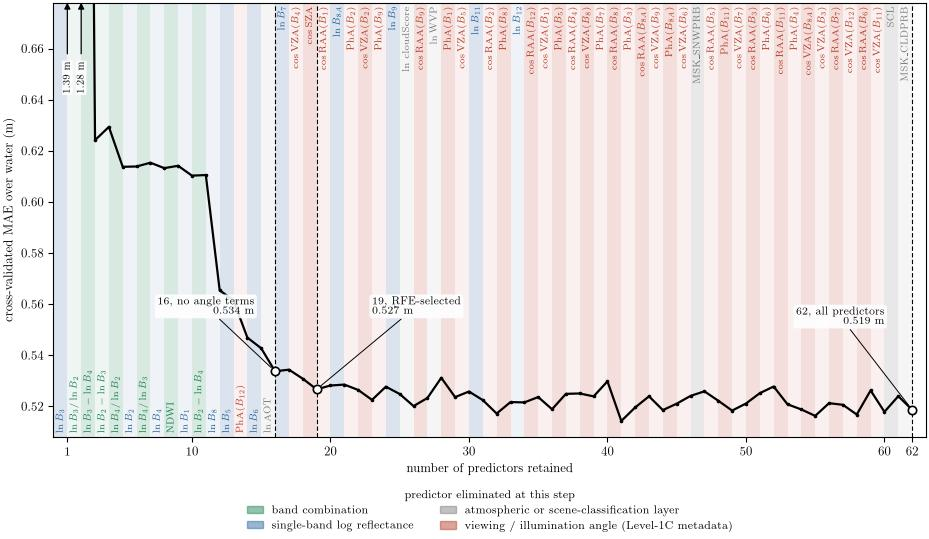

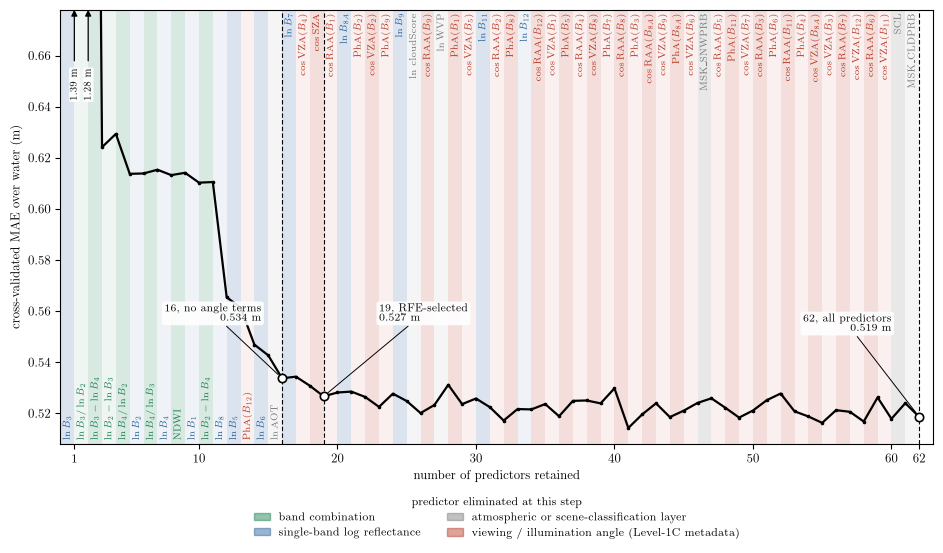

In [2]:
# ============================================================ Figure S1 - recursive feature elimination
# One predictor is dropped per step - always the one with the lowest impurity importance in the
# previous round - and the model is re-cross-validated. The label in each stripe is the predictor
# that was removed from the set of that size, so reading right to left gives the elimination order.
# Band and layer abbreviations are spelled out in the caption rather than on the figure.

YLIM = (0.508, 0.678)
N_BOTTOM = 16          # predictors eliminated last are labelled along the bottom
# operating point -> (label, text x, text y); the text is tied to its marker by a leader line
MARKS = {62: ('62, all predictors', 60.0, 0.5515),
         19: ('19, RFE-selected', 23.0, 0.5555),
         16: ('16, no angle terms', 14.5, 0.5555)}

plt.close('all')
fig, ax = plt.subplots(figsize=[9.5, 5.6], dpi=100)

# alternating stripes, one per elimination step, tinted by the category of the dropped predictor
for _, it in rfe.iterrows():
    c = CATEGORY_COLOR[category(it.eliminated)]
    ax.axvspan(it.n_feat - 1, it.n_feat, color=c, alpha=0.16 if it.n_feat % 2 else 0.07,
               lw=0, zorder=-3)

ax.plot(rfe.n_feat, rfe.mae, '-', color='k', lw=1.6, zorder=5, solid_capstyle='round')
ax.plot(rfe.n_feat, rfe.mae, '.', color='k', ms=3.2, zorder=6)

for _, it in rfe.iterrows():
    lab, c = pretty(it.eliminated), CATEGORY_COLOR[category(it.eliminated)]
    bottom = it.n_feat <= N_BOTTOM
    ax.text(it.n_feat - 0.5, YLIM[0] + 0.0015 if bottom else YLIM[1] - 0.0015, lab,
            ha='center', va='bottom' if bottom else 'top', rotation='vertical',
            fontsize=6.6, color=c, zorder=7)

for n, (lab, tx, ty) in MARKS.items():
    y = float(rfe.loc[rfe.n_feat == n, 'mae'].iloc[0])
    ax.axvline(n, color='k', lw=0.8, ls=(0, (4, 2)), zorder=4)
    ax.plot(n, y, 'o', mfc='w', mec='k', mew=1.2, ms=6, zorder=8)
    ax.annotate(tex(f'{lab}\n{y:.3f} m'), xy=(n, y), xytext=(tx, ty), zorder=9,
                ha='right' if tx <= n else 'left', va='bottom', fontsize=7.6,
                arrowprops=dict(arrowstyle='-', color='k', lw=0.7, shrinkA=1, shrinkB=4),
                bbox=dict(facecolor='w', alpha=0.9, lw=0, boxstyle='round,pad=0.24'))

# the one- and two-predictor models fall far outside the plotted range
for n in (1, 2):
    y = float(rfe.loc[rfe.n_feat == n, 'mae'].iloc[0])
    assert y > YLIM[1], f'n = {n} is on scale after all ({y:.3f} m)'
    ax.annotate('', xy=(n, YLIM[1]), xytext=(n, YLIM[1] - 0.020), zorder=9,
                arrowprops=dict(arrowstyle='-|>', color='k', lw=0.9, shrinkA=0, shrinkB=0))
    ax.text(n, YLIM[1] - 0.023, tex(f'{y:.2f} m'), ha='center', va='top', fontsize=7,
            rotation='vertical', zorder=9,
            bbox=dict(facecolor='w', alpha=0.9, lw=0, boxstyle='round,pad=0.1'))

ax.set_xlabel(tex('number of predictors retained'))
ax.set_ylabel(tex('cross-validated MAE over water (m)'))
ax.set_xlim(0, 63)
ax.set_ylim(*YLIM)
ax.set_xticks([1] + list(range(10, 63, 10)) + [62])

handles = [matplotlib.patches.Patch(facecolor=CATEGORY_COLOR[k], alpha=0.45,
                                    edgecolor=CATEGORY_COLOR[k], label=tex(CATEGORY_LABEL[k]))
           for k in ('combo', 'band', 'aux', 'angle')]
leg = ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, -0.10), ncol=2,
                fontsize=7.8, frameon=False, handlelength=1.5, columnspacing=2.4,
                title=tex('predictor eliminated at this step'), title_fontsize=8.2)

fig.tight_layout()
figfn = 'figures/sup/figS01_feature-elimination.jpg'
for savefn in [figfn, figfn.replace('.jpg', '.pdf')]:
    fig.savefig(savefn, dpi=300, bbox_inches='tight', pad_inches=0.03)
fig.savefig(figfn.replace('.jpg', '_lowres.jpg'), dpi=100, bbox_inches='tight', pad_inches=0.03)

print('MAE at 62 / 19 / 17 / 16 predictors: ' + ', '.join(
    '%.4f' % rfe.loc[rfe.n_feat == n, 'mae'].iloc[0] for n in (62, 19, 17, 16)))
print('angle predictors surviving to n = 19:',
      [f for f in rfe.eliminated[rfe.n_feat <= 19] if category(f) == 'angle'])
print('the archived 16-predictor model keeps ranks 1-17 except the angle term at rank 14;')
print('  rank 14:', rfe.loc[rfe.n_feat == 14, 'eliminated'].iloc[0],
      '| rank 17:', rfe.loc[rfe.n_feat == 17, 'eliminated'].iloc[0])
display(Image(figfn.replace('.jpg', '_lowres.jpg')))

band ratio           n= 237136  MAE 1.558  RMSE 2.738  bias -0.288  r 0.560
random forest, 62    n= 237136  MAE 0.543  RMSE 1.059  bias -0.062  r 0.946
random forest, 16    n= 237136  MAE 0.566  RMSE 1.075  bias -0.065  r 0.944
band ratio refitted on every sample instead of out of fold: MAE 1.557 m


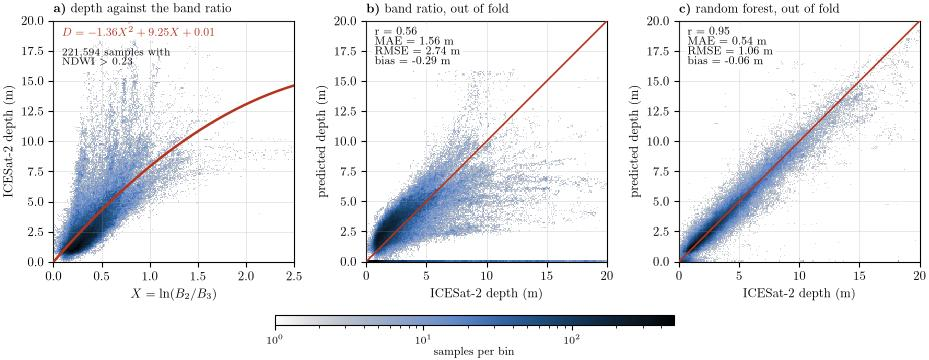

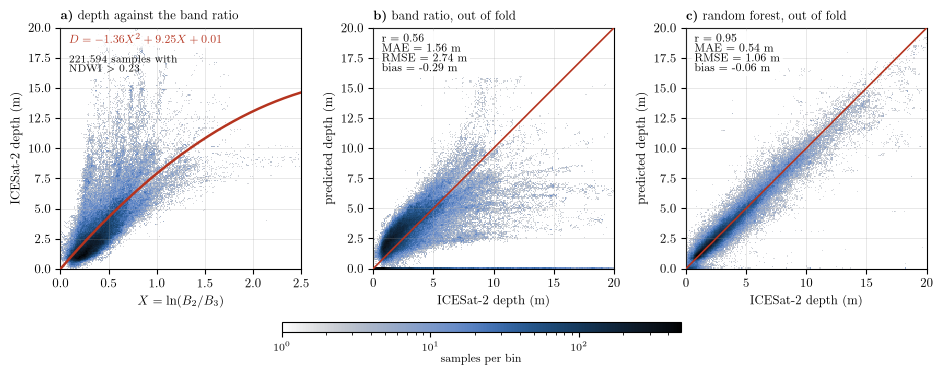

In [3]:
# ============================================================ Figure S2 - the band-ratio baseline
# A quadratic in X = ln(B2/B3) is fitted to the training segments of each fold and applied to the
# held-out ones, so the band ratio and the random forest are scored on exactly the same samples.

DMAX, XMAX = 20.0, 2.5
CMAP, GRIDC = cmc.oslo_r, '#9a9a9a'

X = smp.bandratio_X.to_numpy(dtype=float)
fit_mask = np.isfinite(X) & (smp.ndwi.to_numpy() > NDWI_THRESH) & WET
coef = np.asarray(meta['band_ratio_coefficients_all_samples'], dtype=float)

s_br, s_rf, s_rf16 = score(smp.br_pred), score(smp.rf_pred), score(smp.rf16_pred)
assert s_br['n'] == s_rf['n'] == int(WET.sum()), 'panels b and c must score the same samples'


def density(ax, x, y, xmax, ymax, bins=220):
    m = np.isfinite(x) & np.isfinite(y)
    h, xe, ye = np.histogram2d(x[m], y[m], bins=bins, range=[[0, xmax], [0, ymax]])
    h[h == 0] = np.nan
    return ax.pcolormesh(xe, ye, h.T, cmap=CMAP, norm=LogNorm(vmin=1, vmax=np.nanmax(h)),
                         rasterized=True, zorder=2)


plt.close('all')
fig, axs = plt.subplots(figsize=[9.5, 3.55], ncols=3, dpi=100)

# ---- (a) the relationship the band-ratio method assumes
ax = axs[0]
pcm = density(ax, X[fit_mask], OBS[fit_mask], XMAX, DMAX)
xf = np.linspace(0, XMAX, 200)
ax.plot(xf, np.clip(np.polyval(coef, xf), 0, None), '-', color='#b5341f', lw=1.8, zorder=4)
ax.set_xlabel(r'$X = \ln(B_2 / B_3)$')
ax.set_ylabel(tex('ICESat-2 depth (m)'))
ax.set_xlim(0, XMAX)
ax.set_ylim(0, DMAX)
ax.text(0.035, 0.975, tex('$D = %.2f X^2 + %.2f X %+.2f$' % tuple(coef)) if USETEX
        else '$D = %.2f X^2 + %.2f X %+.2f$' % tuple(coef),
        transform=ax.transAxes, ha='left', va='top', fontsize=8, color='#b5341f', zorder=6,
        bbox=dict(facecolor='w', alpha=0.85, lw=0, boxstyle='round,pad=0.25'))
ax.text(0.035, 0.885, tex(f'{int(fit_mask.sum()):,} samples with\nNDWI > {NDWI_THRESH}'),
        transform=ax.transAxes, ha='left', va='top', fontsize=7.4, zorder=6)
ax.set_title(bold(tex('a)')) + tex('  depth against the band ratio'), loc='left', fontsize=9)

# ---- (b) and (c) the two models on identical held-out samples
for ax, pred, s, ttl in ((axs[1], smp.br_pred, s_br, 'b)  band ratio, out of fold'),
                         (axs[2], smp.rf_pred, s_rf, 'c)  random forest, out of fold')):
    density(ax, OBS[WET], np.asarray(pred, dtype=float)[WET], DMAX, DMAX)
    ax.plot([0, DMAX], [0, DMAX], '-', color='#b5341f', lw=1.2, zorder=4)
    ax.set_xlabel(tex('ICESat-2 depth (m)'))
    ax.set_ylabel(tex('predicted depth (m)'))
    ax.set_xlim(0, DMAX)
    ax.set_ylim(0, DMAX)
    ax.set_aspect(1)
    ax.text(0.035, 0.975, statbox(s), transform=ax.transAxes, ha='left', va='top', fontsize=8,
            linespacing=1.45, zorder=6,
            bbox=dict(facecolor='w', alpha=0.85, lw=0, boxstyle='round,pad=0.25'))
    head, rest = ttl.split('  ', 1)
    ax.set_title(bold(tex(head)) + tex('  ' + rest), loc='left', fontsize=9)

for ax in axs:
    ax.grid(True, color=GRIDC, lw=0.4, alpha=0.4, zorder=1)
    ax.set_axisbelow(False)

fig.tight_layout(rect=(0, 0.085, 1, 1))
cax = fig.add_axes([0.30, 0.055, 0.42, 0.028])
cb = fig.colorbar(pcm, cax=cax, orientation='horizontal')
cb.set_label(tex('samples per bin'), fontsize=8, labelpad=1)
cb.ax.tick_params(labelsize=7.5)

figfn = 'figures/sup/figS02_band-ratio-baseline.jpg'
for savefn in [figfn, figfn.replace('.jpg', '.pdf')]:
    fig.savefig(savefn, dpi=300, bbox_inches='tight', pad_inches=0.03)
fig.savefig(figfn.replace('.jpg', '_lowres.jpg'), dpi=100, bbox_inches='tight', pad_inches=0.03)

for name, s in (('band ratio', s_br), ('random forest, 62', s_rf), ('random forest, 16', s_rf16)):
    print('%-20s n=%7d  MAE %5.3f  RMSE %5.3f  bias %+5.3f  r %.3f'
          % (name, s['n'], s['MAE'], s['RMSE'], s['bias'], s['r']))
print('band ratio refitted on every sample instead of out of fold: MAE %.3f m'
      % score(smp.br_pred_insample)['MAE'])
display(Image(figfn.replace('.jpg', '_lowres.jpg')))

median depth at X = 0.60 across the six example icesat-2 lake segments: 3.4, 5.9, 10.6, 7.9, 2.9, 5.8 m   (the global fit says 5.1 m)
median depth at X = 0.25 across the six example sentinel-2 scenes: 1.2, 1.5, 1.5, 1.5, 1.8, 5.6 m   (the global fit says 2.2 m)


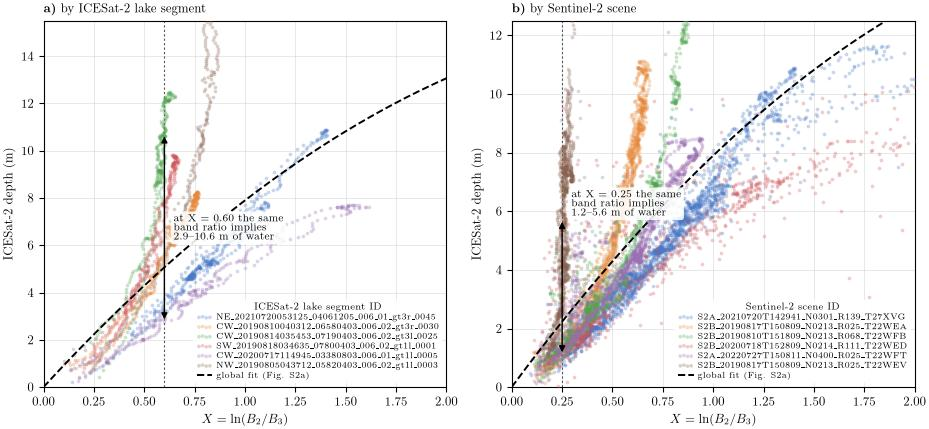

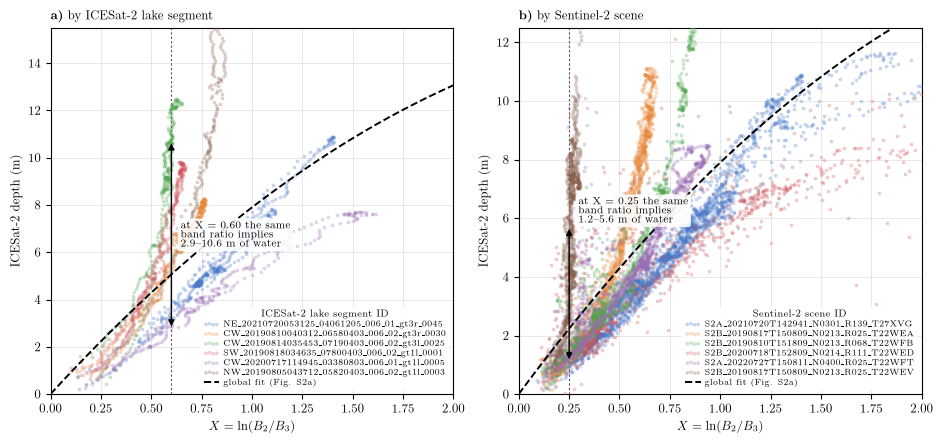

In [4]:
# ============================================================ Figure S3 - why the band ratio does not transfer
# Within one lake, or within one scene, depth and the band ratio track each other closely. The
# slope of that relationship is what changes from lake to lake and from scene to scene, so no
# single set of coefficients fits them all. Same six segments and six scenes as the thesis.
# The probe value differs between the panels only because it has to be one that every example
# actually covers: the six scenes do not overlap at X = 0.6.

SEG_IDX = [1, 2, 4, 5, 6, 11]      # rank among single-scene segments, by mean bathymetry confidence
SCENE_IDX = [2, 3, 6, 11, 13, 23]  # rank among scenes with > 1000 wet samples, by mean confidence
PROBE_HALFWIDTH, PROBE_MIN_N = 0.03, 10
PAL = ['#4878c8', '#e8893a', '#4ea64e', '#d1555a', '#9a6fb5', '#8a6250']


def short(i, col):
    """Legend labels: keep only the part of an ID that varies between the examples.

    Every segment ID starts GrIS_; every scene ID carries MSIL2A_ and, after the last
    underscore, the processing time rather than the acquisition time (which is already in the
    ID). Dropping those roughly halves the legend width.
    """
    s = str(i)
    if col == 'IS2_id':
        assert s.startswith('GrIS_'), s
        return s[len('GrIS_'):]
    assert '_MSIL2A_' in s and s.count('_') >= 2, s
    return s.replace('MSIL2A_', '', 1).rsplit('_', 1)[0]


seg_sel = seg[seg.n_scenes == 1].sort_values('conf_mean', ascending=False).index
wet_scene = smp[WET].groupby('S2_id', observed=True)['lat'].count()
big = wet_scene[wet_scene > 1000].index
scene_sel = (smp[smp.S2_id.isin(big)].groupby('S2_id', observed=True)['conf'].mean()
             .sort_values(ascending=False).index)
assert len(seg_sel) >= max(SEG_IDX) + 1 and len(scene_sel) >= max(SCENE_IDX) + 1

usable = np.isfinite(X) & (smp.ndwi.to_numpy() > NDWI_THRESH) & WET
sub = smp[usable].copy()
sub['X'] = X[usable]

plt.close('all')
fig, axs = plt.subplots(figsize=[9.5, 4.5], ncols=2, dpi=100)
xf = np.linspace(0, 2, 200)
probes = {}

for ax, col, ids, ttl, what, ymax, x_probe, note_va in (
        (axs[0], 'IS2_id', [seg_sel[i] for i in SEG_IDX],
         'a)  by ICESat-2 lake segment', 'ICESat-2 lake segment', 15.5, 0.60, 'center'),
        (axs[1], 'S2_id', [scene_sel[i] for i in SCENE_IDX],
         'b)  by Sentinel-2 scene', 'Sentinel-2 scene', 12.5, 0.25, 'bottom')):
    med = []
    for j, i in enumerate(ids):
        d = sub[sub[col] == i]
        ax.scatter(d.X, d.depth, s=7, color=PAL[j], alpha=0.30, lw=0, rasterized=True,
                   label=tex(short(i, col)), zorder=3)
        near = d[np.abs(d.X - x_probe) < PROBE_HALFWIDTH]
        med.append(float(near.depth.median()) if len(near) >= PROBE_MIN_N else np.nan)
    # shortening must not make two examples share a label
    assert len({short(i, col) for i in ids}) == len(ids), f'{what}: labels collide'
    # the whole point of the panel is that every example is represented at the probe value
    assert np.isfinite(med).all(), f'{what}: no samples near X = {x_probe} for some example'
    probes[what] = (x_probe, med)

    ax.plot(xf, np.clip(np.polyval(coef, xf), 0, None), '--', color='k', lw=1.4, zorder=5,
            label=tex('global fit (Fig. S2a)'))
    ax.axvline(x_probe, color='#555555', lw=0.8, ls=(0, (2, 2)), zorder=2)
    ax.annotate('', xy=(x_probe, min(med)), xytext=(x_probe, max(med)), zorder=6,
                arrowprops=dict(arrowstyle='<|-|>', color='k', lw=1.0,
                                shrinkA=0, shrinkB=0, mutation_scale=9))
    ax.text(x_probe + 0.045,
            (min(med) + max(med)) / 2 if note_va == 'center' else max(med) + 0.15,
            tex(f'at X = {x_probe:.2f} the same\nband ratio implies\n'
                f'{min(med):.1f}–{max(med):.1f} m of water'),
            ha='left', va=note_va, fontsize=7.4, zorder=7, linespacing=1.4,
            bbox=dict(facecolor='w', alpha=0.88, lw=0, boxstyle='round,pad=0.26'))

    ax.set_xlabel(r'$X = \ln(B_2 / B_3)$')
    ax.set_ylabel(tex('ICESat-2 depth (m)'))
    ax.set_xlim(0, 2)
    ax.set_ylim(0, ymax)
    head, rest = ttl.split('  ', 1)
    ax.set_title(bold(tex(head)) + tex('  ' + rest), loc='left', fontsize=9)
    leg = ax.legend(loc='lower right', scatterpoints=4, fontsize=5.6, borderpad=0.45,
                    labelspacing=0.35, handletextpad=0.5, framealpha=0.92,
                    title=tex(f'{what} ID'), title_fontsize=6.6)
    leg.get_frame().set_linewidth(0.0)
    ax.grid(True, color='#9a9a9a', lw=0.4, alpha=0.4, zorder=1)

fig.tight_layout()
figfn = 'figures/sup/figS03_band-ratio-by-segment-and-scene.jpg'
for savefn in [figfn, figfn.replace('.jpg', '.pdf')]:
    fig.savefig(savefn, dpi=300, bbox_inches='tight', pad_inches=0.03)
fig.savefig(figfn.replace('.jpg', '_lowres.jpg'), dpi=100, bbox_inches='tight', pad_inches=0.03)

for what, (x_probe, med) in probes.items():
    print(f'median depth at X = {x_probe:.2f} across the six example {what.lower()}s: '
          + ', '.join('%.1f' % v for v in med)
          + ' m   (the global fit says %.1f m)' % np.polyval(coef, x_probe))
display(Image(figfn.replace('.jpg', '_lowres.jpg')))